# Module 11 — Likelihood and Bayesian Inference

This notebook is the runnable companion to the concept guide: read [README.md](README.md) first, or keep
it open alongside. Each section mirrors a numbered section of the guide. We draw the likelihood curve of a
coin, derive and check the closed-form MLEs, fit a Gamma distribution numerically three different ways,
verify the Fisher-information formula for standard errors by simulation, show by code that minimising MSE
*is* Gaussian maximum likelihood and that cross-entropy *is* the Bernoulli log-likelihood, update Beta and
Normal posteriors, turn a Gaussian prior into ridge regression, compare predictive intervals with plug-in
ones, and finish with a Bayesian A/B test.

Everything is built from scratch in NumPy first; `scipy` and `scikit-learn` appear afterwards to confirm the
hand computation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb
from scipy import stats, optimize, special
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. The likelihood function

Seven heads in ten flips. Under a Binomial model with head probability $p$,

$$L(p) = \binom{10}{7}p^7(1-p)^3, \qquad \ell(p) = \log L(p).$$

We tabulate $L$ on a grid of $p$, plot both $L$ and $\ell$, and check two claims from the guide: the
curve peaks at $p = 0.7$, and $L$ is **not** a probability distribution over $p$ (its integral is $1/11$,
not 1).

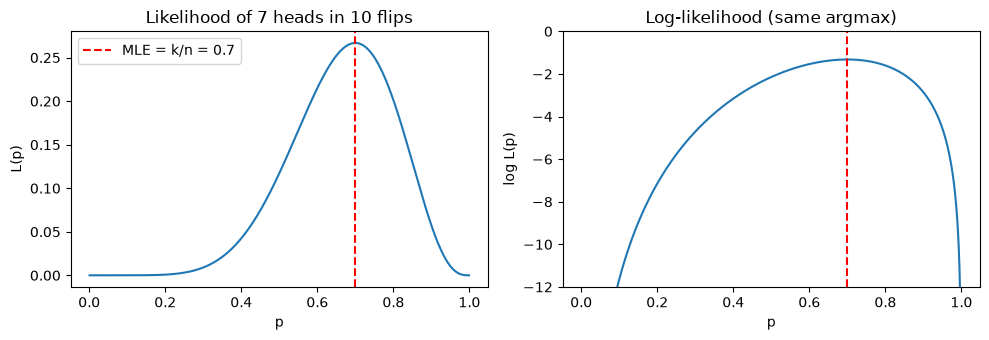

p = 0.5:  L = 0.1172   log L = -2.1440
p = 0.6:  L = 0.2150   log L = -1.5372
p = 0.7:  L = 0.2668   log L = -1.3212
p = 0.8:  L = 0.2013   log L = -1.6028
p = 0.9:  L = 0.0574   log L = -2.8578

argmax on the grid: p = 0.700
likelihood ratio L(0.7)/L(0.5) = 2.277
integral of L over p in [0,1] = 0.0909   (= 1/11 = 0.0909, so L is not a density in p)


In [2]:
k, n = 7, 10
p_grid = np.linspace(0.001, 0.999, 999)

def binom_lik(p, k, n):
    return comb(n, k) * p**k * (1 - p)**(n - k)

L = binom_lik(p_grid, k, n)
logL = np.log(L)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(p_grid, L); ax1.axvline(k / n, color="r", ls="--", label=f"MLE = k/n = {k/n}")
ax1.set_xlabel("p"); ax1.set_ylabel("L(p)"); ax1.set_title(f"Likelihood of {k} heads in {n} flips"); ax1.legend()
ax2.plot(p_grid, logL); ax2.axvline(k / n, color="r", ls="--")
ax2.set_ylim(-12, 0); ax2.set_xlabel("p"); ax2.set_ylabel("log L(p)"); ax2.set_title("Log-likelihood (same argmax)")
plt.tight_layout(); plt.show()

for p in (0.5, 0.6, 0.7, 0.8, 0.9):
    print(f"p = {p}:  L = {binom_lik(p, k, n):.4f}   log L = {np.log(binom_lik(p, k, n)):.4f}")
print(f"\nargmax on the grid: p = {p_grid[np.argmax(L)]:.3f}")
print(f"likelihood ratio L(0.7)/L(0.5) = {binom_lik(0.7, k, n)/binom_lik(0.5, k, n):.3f}")
print(f"integral of L over p in [0,1] = {np.trapezoid(L, p_grid):.4f}   (= 1/{n + 1} = {1/(n + 1):.4f}, so L is not a density in p)")

Both curves peak at the same $p$ — the logarithm is monotone, so maximising $\ell$ and maximising $L$ are
the same problem, and $\ell$ is the one you can differentiate and sum. The integral of $L$ over $p$ is
$1/11$: the likelihood ranks parameter values but assigns no probability to them. The ratio
$L(0.7)/L(0.5) = 2.28$ says the data prefer a 70% coin to a fair one, but only mildly.

**Try it yourself:** change `k, n` to `70, 100` and re-run. How much narrower is the peak, and what is the
likelihood ratio now?

## 2. Analytic maximum likelihood

Setting the score (derivative of $\ell$) to zero gives closed forms: Normal $\hat\mu = \bar x$,
$\hat\sigma^2 = \frac1n\sum(x_i - \bar x)^2$; Poisson $\hat\lambda = \bar x$; Exponential
$\hat\lambda = 1/\bar x$. We compute each by hand on the guide's data and confirm with
`scipy.optimize.minimize` on the negative log-likelihood — the general-purpose route of Section 3.

In [3]:
x_norm = np.array([2.1, 3.4, 1.9, 4.0, 2.6])
calls = np.array([3, 5, 2, 4, 6, 4])
repair = np.array([2.0, 0.5, 1.5, 4.0])

# closed forms
mu_hat, var_hat = x_norm.mean(), x_norm.var()                   # ddof=0: the MLE
print(f"Normal:      mu_hat = {mu_hat:.3f}   sigma^2_hat (MLE, /n) = {var_hat:.4f}   unbiased s^2 (/(n-1)) = {x_norm.var(ddof=1):.4f}")
print(f"Poisson:     lambda_hat = mean = {calls.mean():.3f} calls/hour")
print(f"Exponential: lambda_hat = 1/mean = {1/repair.mean():.3f} per hour;  by invariance P(T > 3h) = exp(-3 lambda_hat) = {np.exp(-3/repair.mean()):.4f}")

# the same answers from a numerical optimiser on the negative log-likelihood
def nll_normal(theta, x):
    mu, log_sigma = theta
    sigma = np.exp(log_sigma)                                    # reparameterise so sigma > 0
    return 0.5 * len(x) * np.log(2 * np.pi * sigma**2) + np.sum((x - mu)**2) / (2 * sigma**2)

res = optimize.minimize(nll_normal, x0=[0.0, 0.0], args=(x_norm,), method="BFGS")
print(f"\nnumeric Normal MLE: mu = {res.x[0]:.4f}, sigma^2 = {np.exp(2*res.x[1]):.4f}   (closed form {mu_hat:.4f}, {var_hat:.4f})")

nll_poisson = lambda log_lam, x: -np.sum(x * log_lam - np.exp(log_lam) - special.gammaln(x + 1))
res_p = optimize.minimize(nll_poisson, x0=[0.0], args=(calls,), method="BFGS")
print(f"numeric Poisson MLE: lambda = {np.exp(res_p.x[0]):.4f}   (closed form {calls.mean():.4f})")

# the bias of the variance MLE, seen by simulation
sims = rng.normal(0, 1, size=(20_000, 5))
print(f"\nE[sigma^2_hat] for n = 5 and sigma^2 = 1: simulated {sims.var(axis=1).mean():.4f}   theory (n-1)/n = {4/5:.4f}")

Normal:      mu_hat = 2.800   sigma^2_hat (MLE, /n) = 0.6280   unbiased s^2 (/(n-1)) = 0.7850
Poisson:     lambda_hat = mean = 4.000 calls/hour
Exponential: lambda_hat = 1/mean = 0.500 per hour;  by invariance P(T > 3h) = exp(-3 lambda_hat) = 0.2231

numeric Normal MLE: mu = 2.8000, sigma^2 = 0.6280   (closed form 2.8000, 0.6280)
numeric Poisson MLE: lambda = 4.0000   (closed form 4.0000)

E[sigma^2_hat] for n = 5 and sigma^2 = 1: simulated 0.8052   theory (n-1)/n = 0.8000


Optimiser and formula agree to four decimals, which is the point: closed forms are a luxury, the NLL is
always available. Note the variance: the MLE divides by $n$ and averages $0.8\sigma^2$ over repeated samples
of size 5 — biased low by the factor $(n-1)/n$, exactly as the guide derives. Note also the
reparameterisation `log_sigma`: the optimiser explores all of $\mathbb{R}$ while $\sigma$ stays positive.

## 3. Numerical maximum likelihood: the Gamma distribution

For Gamma$(\alpha, \beta)$ data, $\hat\beta = \hat\alpha/\bar x$ in closed form, but $\hat\alpha$ solves
$\log\alpha - \psi(\alpha) = \log\bar x - \overline{\log x}$ with $\psi$ the digamma function — no closed
form. Three routes to the same answer: Newton's method on this one-dimensional profile equation, BFGS on the
two-parameter NLL in $(\log\alpha, \log\beta)$, and `scipy.stats.gamma.fit`. Then we draw the
log-likelihood surface.

In [4]:
x_g = np.array([1.2, 2.5, 0.8, 3.1, 1.9])
xbar, s = x_g.mean(), np.log(x_g.mean()) - np.log(x_g).mean()
print(f"xbar = {xbar:.3f}   s = log(xbar) - mean(log x) = {s:.4f}")

# (a) Newton's method on the profile equation f(alpha) = log(alpha) - digamma(alpha) - s = 0
f  = lambda a: np.log(a) - special.digamma(a) - s
fp = lambda a: 1/a - special.polygamma(1, a)
alpha = xbar**2 / x_g.var()                       # method-of-moments start
for it in range(6):
    print(f"  Newton iteration {it}: alpha = {alpha:.6f}   f(alpha) = {f(alpha):+.2e}")
    step = f(alpha) / fp(alpha)
    alpha -= step
    if abs(step) < 1e-10:
        break
alpha_newton, beta_newton = alpha, alpha / xbar
print(f"(a) Newton:        alpha = {alpha_newton:.5f}, beta = {beta_newton:.5f}")

# (b) BFGS on the full two-parameter negative log-likelihood, in log-parameters
def nll_gamma(theta, x):
    a, b = np.exp(theta)
    return -np.sum(stats.gamma.logpdf(x, a, scale=1/b))

res_g = optimize.minimize(nll_gamma, x0=[0.0, 0.0], args=(x_g,), method="BFGS")
alpha_bfgs, beta_bfgs = np.exp(res_g.x)
print(f"(b) BFGS on NLL:   alpha = {alpha_bfgs:.5f}, beta = {beta_bfgs:.5f}   ({res_g.nfev} function evaluations)")

# (c) scipy's built-in fit (floc=0 fixes the location at zero; it returns shape, loc, scale = 1/beta)
a_sp, _, scale_sp = stats.gamma.fit(x_g, floc=0)
print(f"(c) scipy fit:     alpha = {a_sp:.5f}, beta = {1/scale_sp:.5f}")

xbar = 1.900   s = log(xbar) - mean(log x) = 0.1121
  Newton iteration 0: alpha = 5.157143   f(alpha) = -1.20e-02
  Newton iteration 1: alpha = 4.555606   f(alpha) = +1.64e-03
  Newton iteration 2: alpha = 4.619170   f(alpha) = +2.33e-05
  Newton iteration 3: alpha = 4.620099   f(alpha) = +4.85e-09
  Newton iteration 4: alpha = 4.620099   f(alpha) = +2.22e-16
(a) Newton:        alpha = 4.62010, beta = 2.43163
(b) BFGS on NLL:   alpha = 4.62010, beta = 2.43163   (36 function evaluations)
(c) scipy fit:     alpha = 4.62010, beta = 2.43163


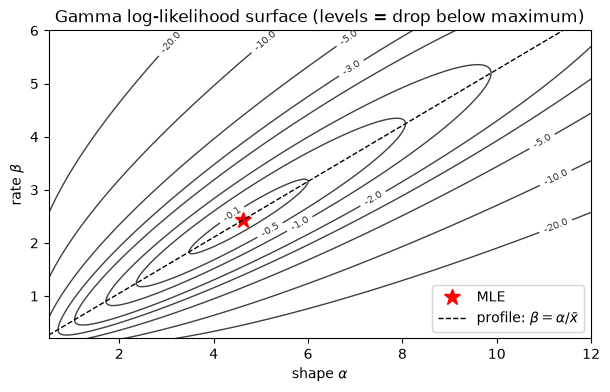

inverse Fisher matrix at the MLE: SE(alpha) = 2.82, SE(beta) = 1.57, correlation = 0.947


In [5]:
A, B = np.meshgrid(np.linspace(0.5, 12, 200), np.linspace(0.2, 6, 200))
n_g = len(x_g)
LL = n_g * A * np.log(B) - n_g * special.gammaln(A) + (A - 1) * np.log(x_g).sum() - B * x_g.sum()
LL_max = LL.max()
cs = plt.contour(A, B, LL, levels=LL_max - np.array([20, 10, 5, 3, 2, 1, 0.5, 0.1]), colors="0.25", linewidths=1, linestyles="solid")
plt.clabel(cs, fmt=lambda v: f"{v - LL_max:.1f}", fontsize=7)
plt.plot(alpha_bfgs, beta_bfgs, "r*", ms=12, label="MLE")
plt.plot(np.linspace(0.5, 12, 50), np.linspace(0.5, 12, 50) / xbar, "k--", lw=1, label=r"profile: $\beta = \alpha/\bar{x}$")
plt.ylim(0.2, 6)
plt.xlabel(r"shape $\alpha$"); plt.ylabel(r"rate $\beta$"); plt.title("Gamma log-likelihood surface (levels = drop below maximum)")
plt.legend(loc="lower right"); plt.show()

# the curvature at the summit, as standard errors: invert the Fisher information matrix
fisher_g = n_g * np.array([[special.polygamma(1, alpha_newton), -1 / beta_newton],
                           [-1 / beta_newton, alpha_newton / beta_newton**2]])
cov_g = np.linalg.inv(fisher_g)
print(f"inverse Fisher matrix at the MLE: SE(alpha) = {np.sqrt(cov_g[0, 0]):.2f}, SE(beta) = {np.sqrt(cov_g[1, 1]):.2f}, "
      f"correlation = {cov_g[0, 1] / np.sqrt(cov_g[0, 0] * cov_g[1, 1]):.3f}")

Three methods, one summit: $\hat\alpha = 4.620$, $\hat\beta = 2.432$. The contour plot explains why the
one-dimensional Newton route works: the dashed line $\beta = \alpha/\bar x$ is the ridge of the surface, and
the full MLE lies on it. Notice how long that diagonal ridge is: $\alpha$ and $\beta$ are strongly correlated
in the likelihood (a larger shape with a larger rate fits almost as well), so with five data points neither is
pinned down precisely. The inverse Fisher matrix puts numbers on it: $\operatorname{SE}(\hat\alpha) \approx 2.8$,
$\operatorname{SE}(\hat\beta) \approx 1.6$ and a correlation of about $0.95$. Section 4 develops this
curvature-to-standard-error link for one-parameter models.

**Try it yourself:** generate `x_g = rng.gamma(4.62, 1/2.43, size=500)` and re-run — watch the contours
tighten around the truth.

## 4. Fisher information and standard errors, checked by simulation

The guide derives $i(p) = 1/(p(1-p))$ for a Bernoulli trial and $i(\lambda) = 1/\lambda$ for a Poisson
count, so the MLE's standard error should be $\operatorname{SE} = 1/\sqrt{n\,i(\theta)}$. We generate 5,000
datasets of each size, compute the MLE on each, and compare the empirical standard deviation of the MLEs with
the formula; then we check that the Wald interval $\hat\theta \pm 1.96\,\operatorname{SE}(\hat\theta)$
covers the truth about 95% of the time.

     n |  sd(p_hat)  1/sqrt(n i(p))  Wald coverage |  sd(lam_hat)  sqrt(lam/n)  Wald coverage
    10 |     0.1439          0.1449          0.850 |       0.6330       0.6325          0.945
    30 |     0.0831          0.0837          0.956 |       0.3616       0.3651          0.952


   100 |     0.0461          0.0458          0.946 |       0.1965       0.2000          0.953


   300 |     0.0261          0.0265          0.951 |       0.1140       0.1155          0.949


  1000 |     0.0145          0.0145          0.950 |       0.0628       0.0632          0.952


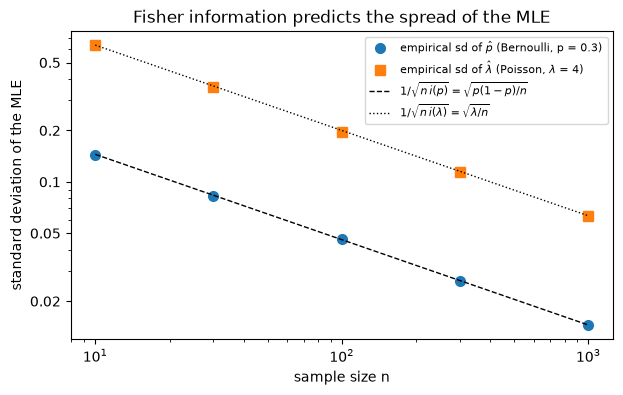


observed information for 7 heads in 10 at p_hat = 0.7: 7/0.7^2 + 3/0.3^2 = 47.62 = n/(p(1-p)) = 47.62
-> SE = 1/sqrt(47.6) = 0.1449;  95% Wald interval [0.416, 0.984]


In [6]:
from matplotlib.ticker import NullFormatter

p_true, lam_true, reps = 0.3, 4.0, 5_000
ns = np.array([10, 30, 100, 300, 1_000])
print(f"{'n':>6s} | {'sd(p_hat)':>10s} {'1/sqrt(n i(p))':>15s} {'Wald coverage':>14s} | {'sd(lam_hat)':>12s} {'sqrt(lam/n)':>12s} {'Wald coverage':>14s}")
sd_p, sd_l = [], []
for n_ in ns:
    p_hat = rng.binomial(n_, p_true, size=reps) / n_
    se_p = np.sqrt(np.clip(p_hat * (1 - p_hat), 1e-12, None) / n_)             # SE evaluated at the estimate
    cover_p = np.mean(np.abs(p_hat - p_true) <= 1.96 * se_p)
    lam_hat = rng.poisson(lam_true, size=(reps, n_)).mean(axis=1)
    se_l = np.sqrt(lam_hat / n_)
    cover_l = np.mean(np.abs(lam_hat - lam_true) <= 1.96 * se_l)
    sd_p.append(p_hat.std()); sd_l.append(lam_hat.std())
    print(f"{n_:6d} | {p_hat.std():10.4f} {np.sqrt(p_true*(1-p_true)/n_):15.4f} {cover_p:14.3f} | {lam_hat.std():12.4f} {np.sqrt(lam_true/n_):12.4f} {cover_l:14.3f}")

plt.loglog(ns, sd_p, "o", ms=7, label=r"empirical sd of $\hat p$ (Bernoulli, p = 0.3)")
plt.loglog(ns, sd_l, "s", ms=7, label=r"empirical sd of $\hat\lambda$ (Poisson, $\lambda$ = 4)")
plt.loglog(ns, np.sqrt(p_true*(1-p_true)/ns), "k--", lw=1, label=r"$1/\sqrt{n\,i(p)} = \sqrt{p(1-p)/n}$")
plt.loglog(ns, np.sqrt(lam_true/ns), "k:", lw=1, label=r"$1/\sqrt{n\,i(\lambda)} = \sqrt{\lambda/n}$")
plt.yticks([0.02, 0.05, 0.1, 0.2, 0.5], ["0.02", "0.05", "0.1", "0.2", "0.5"])
plt.gca().yaxis.set_minor_formatter(NullFormatter())
plt.xlabel("sample size n"); plt.ylabel("standard deviation of the MLE"); plt.title("Fisher information predicts the spread of the MLE")
plt.legend(fontsize=8); plt.show()

# the Cramer-Rao bound is attained exactly by the sample proportion: its variance IS p(1-p)/n
print(f"\nobserved information for 7 heads in 10 at p_hat = 0.7: 7/0.7^2 + 3/0.3^2 = {7/0.49 + 3/0.09:.2f} = n/(p(1-p)) = {10/0.21:.2f}")
print(f"-> SE = 1/sqrt(47.6) = {1/np.sqrt(10/0.21):.4f};  95% Wald interval [{0.7 - 1.96/np.sqrt(10/0.21):.3f}, {0.7 + 1.96/np.sqrt(10/0.21):.3f}]")

The empirical standard deviations (the markers) sit on the dashed and dotted theory lines at every $n$, with
the familiar slope $-1/2$ on log–log axes. The coverage columns need more care. For $p = 0.3$ the simulated coverage at the sample
sizes in this table is about 95% from $n = 30$ on, but only about 0.85 at $n = 10$ (the normal approximation to
$\hat p$ is poor, and $\hat p = 0$ gives a zero-width interval; these are simulation estimates, and the exact
values follow below), while the Poisson with $\lambda = 4$ is already fine at $n = 10$. The next two plots show where the standard error comes from and how strongly coverage depends on $p$.

  7 heads in   10: curvature J =    47.6   SE = 1/sqrt(J) = 0.1449
 70 heads in  100: curvature J =   476.2   SE = 1/sqrt(J) = 0.0458
700 heads in 1000: curvature J =  4761.9   SE = 1/sqrt(J) = 0.0145


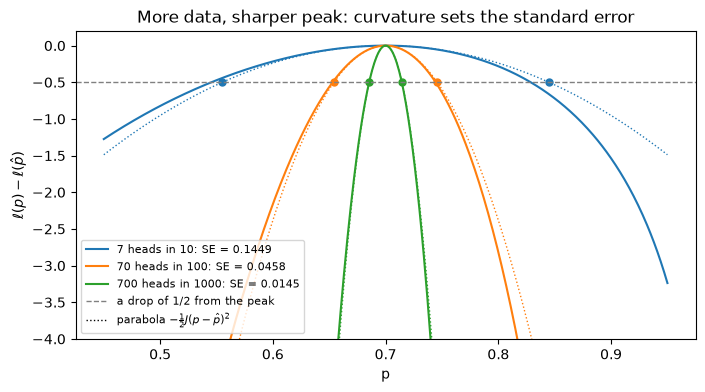

In [7]:
pp = np.linspace(0.45, 0.95, 501)
fig, ax = plt.subplots(figsize=(8, 4))
for (kk, nn), c in zip(((7, 10), (70, 100), (700, 1000)), ("C0", "C1", "C2")):
    ph = kk / nn
    J = nn / (ph * (1 - ph))                               # observed information = curvature at the peak
    se_ = 1 / np.sqrt(J)
    ax.plot(pp, kk * np.log(pp / ph) + (nn - kk) * np.log((1 - pp) / (1 - ph)), c, label=f"{kk} heads in {nn}: SE = {se_:.4f}")
    ax.plot(pp, -0.5 * J * (pp - ph)**2, c, ls=":", lw=1)
    ax.plot([ph - se_, ph + se_], [-0.5, -0.5], c + "o", ms=5)
    print(f"{kk:3d} heads in {nn:4d}: curvature J = {J:7.1f}   SE = 1/sqrt(J) = {se_:.4f}")
ax.axhline(-0.5, color="0.5", ls="--", lw=1, label="a drop of 1/2 from the peak")
ax.plot([], [], "k:", lw=1, label=r"parabola $-\frac{1}{2}J(p - \hat p)^2$")
ax.set_ylim(-4, 0.2); ax.set_xlabel("p"); ax.set_ylabel(r"$\ell(p) - \ell(\hat p)$")
ax.set_title("More data, sharper peak: curvature sets the standard error"); ax.legend(fontsize=8, loc="lower left"); plt.show()

**Notice that** all three curves peak at $0.7$, but each tenfold increase in data multiplies the curvature $J$
by 10 (47.6, 476, 4762), so each curve is $\sqrt{10} \approx 3.2$ times narrower. That answers the first question in
Section 1's *Try it yourself* (the likelihood ratio it also asks for grows from 2.28 to about 3,745). A drop of
$1/2$ in log-likelihood falls close to one standard error from the peak (the dots): within about 1% at $n = 1000$,
about 3% at $n = 100$, and at $n = 10$ the curve crosses at 0.545 and 0.829 instead of 0.555 and 0.845. The dotted
parabola is what the Wald interval assumes; within about two standard errors of the peak it misfits badly only at
$n = 10$.

p = 0.3: n = 10: 0.840,  n = 30: 0.953,  n = 40: 0.930,  n = 100: 0.950,  n = 300: 0.948
p = 0.05: n = 10: 0.400,  n = 30: 0.782,  n = 40: 0.868,  n = 100: 0.877,  n = 300: 0.926


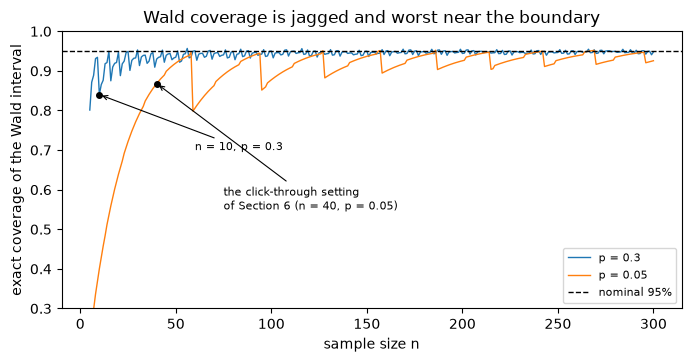

In [8]:
def wald_coverage(n_, p_):
    # exact, by enumeration: add up P(k) over the k whose Wald interval contains p_
    k_ = np.arange(n_ + 1); ph = k_ / n_
    return stats.binom.pmf(k_, n_, p_)[np.abs(ph - p_) <= 1.96 * np.sqrt(ph * (1 - ph) / n_)].sum()

n_axis = np.arange(5, 301)
fig, ax = plt.subplots(figsize=(8, 3.6))
for p_, c in ((0.3, "C0"), (0.05, "C1")):
    ax.plot(n_axis, [wald_coverage(int(n_), p_) for n_ in n_axis], c, lw=1, label=f"p = {p_}")
    print(f"p = {p_}: " + ",  ".join(f"n = {n_}: {wald_coverage(n_, p_):.3f}" for n_ in (10, 30, 40, 100, 300)))
ax.axhline(0.95, color="k", ls="--", lw=1, label="nominal 95%")
ax.annotate("the click-through setting\nof Section 6 (n = 40, p = 0.05)", (40, wald_coverage(40, 0.05)), xytext=(75, 0.55),
            fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
ax.plot(40, wald_coverage(40, 0.05), "ko", ms=4); ax.plot(10, wald_coverage(10, 0.3), "ko", ms=4)
ax.annotate("n = 10, p = 0.3", (10, wald_coverage(10, 0.3)), xytext=(60, 0.7), fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_ylim(0.3, 1); ax.set_xlabel("sample size n"); ax.set_ylabel("exact coverage of the Wald interval")
ax.set_title("Wald coverage is jagged and worst near the boundary"); ax.legend(fontsize=8, loc="lower right"); plt.show()

**Notice that** for $p = 0.3$ coverage is 0.84 at $n = 10$ and from $n \approx 30$ on wobbles between about 0.91 and
0.96, mostly a little under 95%, but for
$p = 0.05$ it is 0.40 at $n = 10$, 0.87 at $n = 40$, 0.88 at $n = 100$ and still 0.93 at $n = 300$: there is no
single sample size at which the interval "starts working". The sawtooth exists because $k$ is discrete: the set of
$k$ whose interval contains $p$ changes only at particular $n$. Each sudden drop is a low value of $k$ leaving that
set (for $p = 0.05$, $k = 1$ leaves at $n = 59$ and coverage falls from 0.95 to 0.80); between drops coverage climbs
as the excluded small $k$ become less likely. Small samples and rates
near the boundary are why we need the exact Beta posterior of Section 6 or the methods of
[Module 12](../12-hypothesis-testing-and-experiments/README.md).

## 5. MLE gives you your loss functions

Two demonstrations. First, for a linear model $y = wx + \varepsilon$ with Gaussian noise, the Gaussian
negative log-likelihood and the mean squared error are different functions of $w$ — but they have the **same
argmin**, because the NLL is an affine function of the SSE. Second, the binary cross-entropy of a
classifier is exactly $-\frac1n\sum_i \log p(y_i \mid p_i)$ under a Bernoulli model.

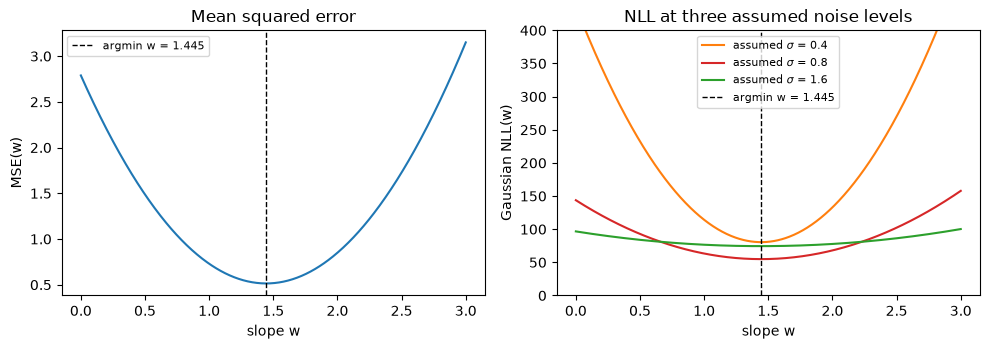

argmin MSE = 1.445   argmin Gaussian NLL = 1.445   closed-form least squares = 1.4447
NLL = 34.790 + SSE/1.28  -> an affine function of SSE, so the minimiser cannot differ

residuals [ 0.5 -1.   0.2  2.  -0.3]: SSE = 5.38, MAE = 0.80
one residual 2.0 -> 4.0:   SSE = 17.38 (x3.2),  MAE = 1.20 (x1.5)


In [9]:
n_pts = 50
x_lin = rng.uniform(-2, 2, size=n_pts)
y_lin = 1.5 * x_lin + rng.normal(0, 0.8, size=n_pts)

w_grid = np.linspace(0, 3, 601)
sse = np.array([np.sum((y_lin - w * x_lin)**2) for w in w_grid])
mse = sse / n_pts
sigma2 = 0.8**2
nll_gauss = 0.5 * n_pts * np.log(2 * np.pi * sigma2) + sse / (2 * sigma2)

w_mse, w_nll = w_grid[np.argmin(mse)], w_grid[np.argmin(nll_gauss)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
ax1.plot(w_grid, mse, "C0"); ax1.axvline(w_mse, color="k", ls="--", lw=1, label=f"argmin w = {w_mse:.3f}")
ax1.set_xlabel("slope w"); ax1.set_ylabel("MSE(w)"); ax1.set_title("Mean squared error"); ax1.legend(fontsize=8)
for s_, c in ((0.4, "C1"), (0.8, "C3"), (1.6, "C2")):
    ax2.plot(w_grid, 0.5 * n_pts * np.log(2 * np.pi * s_**2) + sse / (2 * s_**2), c, label=rf"assumed $\sigma$ = {s_}")
ax2.axvline(w_mse, color="k", ls="--", lw=1, label=f"argmin w = {w_mse:.3f}")
ax2.set_ylim(0, 400); ax2.set_xlabel("slope w"); ax2.set_ylabel("Gaussian NLL(w)"); ax2.set_title("NLL at three assumed noise levels"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

w_closed = (x_lin @ y_lin) / (x_lin @ x_lin)
print(f"argmin MSE = {w_mse:.3f}   argmin Gaussian NLL = {w_nll:.3f}   closed-form least squares = {w_closed:.4f}")
print(f"NLL = {0.5*n_pts*np.log(2*np.pi*sigma2):.3f} + SSE/{2*sigma2:.2f}  -> an affine function of SSE, so the minimiser cannot differ")

# Laplace noise -> MAE, and the robustness difference on an outlier
r = np.array([0.5, -1.0, 0.2, 2.0, -0.3]); r_out = r.copy(); r_out[3] = 4.0
print(f"\nresiduals {r}: SSE = {np.sum(r**2):.2f}, MAE = {np.mean(np.abs(r)):.2f}")
print(f"one residual 2.0 -> 4.0:   SSE = {np.sum(r_out**2):.2f} (x{np.sum(r_out**2)/np.sum(r**2):.1f}),  MAE = {np.mean(np.abs(r_out)):.2f} (x{np.mean(np.abs(r_out))/np.mean(np.abs(r)):.1f})")

**Notice that** the assumed noise level changes both the height of the NLL and its curvature (a smaller
$\sigma$ means a sharper valley), yet the dashed line passes through the bottom of every curve. The noise level
$\sigma$ matters for the uncertainty, not for the least-squares weights.

BCE = 0.42973   -mean log Bernoulli likelihood = 0.42973


sklearn log_loss = 0.42973

cost of assigning 0.7 to the true class: 0.357 nats;  0.1: 2.303 nats;  0.001: 6.908 nats (confident mistakes are punished hardest)

gradient ascent, 2,000 steps: bias 0.8101, weights [ 3.31398435 -2.02428816]
gradient ascent, 10,000 steps: bias 0.8317, weights [ 3.3885814  -2.07031431]
sklearn (unpenalised): bias 0.8317, weights [ 3.38858252 -2.07031501]
log-likelihood: after 2,000 steps -54.044, after 10,000 steps -54.032, sklearn -54.032


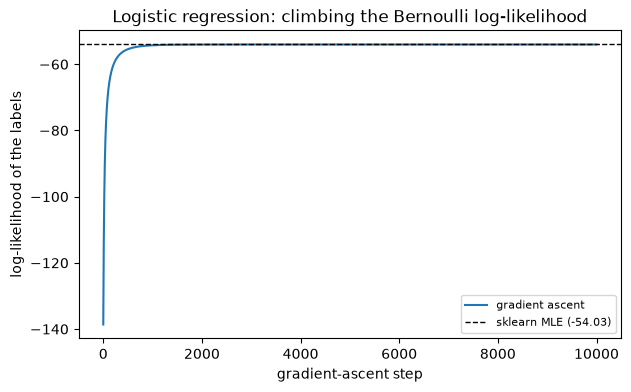

In [10]:
# binary cross-entropy IS the negative mean Bernoulli log-likelihood
def bce(y, p):
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def neg_mean_bernoulli_loglik(y, p):
    lik_each = p**y * (1 - p)**(1 - y)            # p(y_i | p_i) for each example
    return -np.mean(np.log(lik_each))

y_demo = np.array([1, 0, 1, 1, 0]); p_demo = np.array([0.9, 0.2, 0.6, 0.3, 0.1])
print(f"BCE = {bce(y_demo, p_demo):.5f}   -mean log Bernoulli likelihood = {neg_mean_bernoulli_loglik(y_demo, p_demo):.5f}")
from sklearn.metrics import log_loss
print(f"sklearn log_loss = {log_loss(y_demo, p_demo):.5f}")
print(f"\ncost of assigning 0.7 to the true class: {-np.log(0.7):.3f} nats;  0.1: {-np.log(0.1):.3f} nats;  0.001: {-np.log(0.001):.3f} nats (confident mistakes are punished hardest)")

# logistic regression = numerical MLE of the Bernoulli model, trained by gradient ascent on the log-likelihood
X_cls = rng.normal(size=(200, 2))
y_cls = (X_cls @ np.array([1.5, -1.0]) + 0.5 + rng.normal(scale=1.0, size=200) > 0).astype(float)
Xb = np.c_[np.ones(200), X_cls]                       # bias column
sigmoid = lambda z: 1 / (1 + np.exp(-z))

w = np.zeros(3); eta = 0.1; history = []
for step in range(10_000):
    p = sigmoid(Xb @ w)
    grad_ll = Xb.T @ (y_cls - p)                      # d(log-likelihood)/dw = X^T (y - p)   (Module 04/05)
    w += eta * grad_ll / 200
    if step == 1_999:
        w_2000 = w.copy()
    history.append(np.sum(y_cls * np.log(p) + (1 - y_cls) * np.log(1 - p)))

from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(C=np.inf, max_iter=1000, tol=1e-8).fit(X_cls, y_cls)    # C = inf: no penalty, pure MLE
p_sk = clf.predict_proba(X_cls)[:, 1]
ll_sk = -log_loss(y_cls, p_sk, normalize=False)                        # the summed log-likelihood at sklearn's weights
print(f"\ngradient ascent, 2,000 steps: bias {w_2000[0]:.4f}, weights {w_2000[1:]}")
print(f"gradient ascent, 10,000 steps: bias {w[0]:.4f}, weights {w[1:]}")
print(f"sklearn (unpenalised): bias {clf.intercept_[0]:.4f}, weights {clf.coef_[0]}")
print(f"log-likelihood: after 2,000 steps {history[1_999]:.3f}, after 10,000 steps {history[-1]:.3f}, sklearn {ll_sk:.3f}")
plt.plot(history, label="gradient ascent"); plt.axhline(ll_sk, color="k", ls="--", lw=1, label=f"sklearn MLE ({ll_sk:.2f})")
plt.xlabel("gradient-ascent step"); plt.ylabel("log-likelihood of the labels")
plt.title("Logistic regression: climbing the Bernoulli log-likelihood"); plt.legend(fontsize=8); plt.show()

The BCE and the negative mean log-likelihood agree to every digit (and so does `log_loss`): they are the
same formula. Gradient ascent on $\ell(w)$ with the gradient $X^\top(y - p)$ reaches the weights scikit-learn
finds, to four decimals after 10,000 steps, because `LogisticRegression` is a numerical MLE too. It gets
there slowly: the curve looks flat by step 1,000, yet the weights are still about 2% short after 2,000 steps.
The outlier experiment shows the practical content of the Gaussian assumption — one residual doubled multiplies
the SSE by 3.2 but the MAE by only 1.5.

**Try it yourself:** make the classes separable (`y_cls = (X_cls @ np.array([1.5, -1.0]) > 0)`, no noise)
and re-run the gradient-ascent cell: the weights keep growing and the log-likelihood keeps creeping toward
zero — the MLE does not exist.

residual 2 -> 4:  Gaussian 2.92 -> 8.92,  Laplace 2.69 -> 4.69


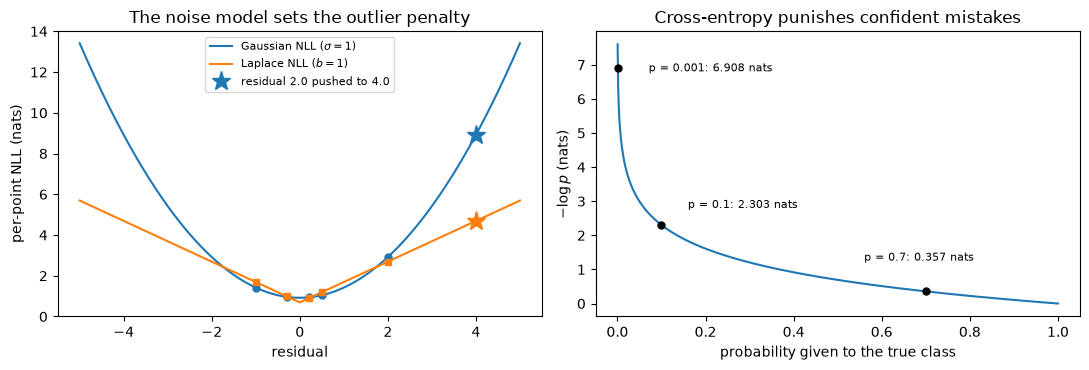

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
gauss_nll = lambda v: 0.5 * np.log(2 * np.pi) + v**2 / 2          # sigma = 1
laplace_nll = lambda v: np.log(2) + np.abs(v)                     # b = 1
rr = np.linspace(-5, 5, 401)
ax1.plot(rr, gauss_nll(rr), "C0", label=r"Gaussian NLL ($\sigma = 1$)"); ax1.plot(rr, laplace_nll(rr), "C1", label=r"Laplace NLL ($b = 1$)")
ax1.plot(r, gauss_nll(r), "C0o", ms=5); ax1.plot(r, laplace_nll(r), "C1s", ms=5)
ax1.plot(4.0, gauss_nll(4.0), "C0*", ms=14, label="residual 2.0 pushed to 4.0"); ax1.plot(4.0, laplace_nll(4.0), "C1*", ms=14)
ax1.set_ylim(0, 14); ax1.set_xlabel("residual"); ax1.set_ylabel("per-point NLL (nats)")
ax1.set_title("The noise model sets the outlier penalty"); ax1.legend(fontsize=8, loc="upper center")
print(f"residual 2 -> 4:  Gaussian {gauss_nll(2.0):.2f} -> {gauss_nll(4.0):.2f},  Laplace {laplace_nll(2.0):.2f} -> {laplace_nll(4.0):.2f}")

pv = np.linspace(0.0005, 1, 800)
ax2.plot(pv, -np.log(pv), "C0")
for q, dx, dy in ((0.7, -0.14, 0.9), (0.1, 0.06, 0.5), (0.001, 0.07, -0.1)):
    ax2.plot(q, -np.log(q), "ko", ms=5)
    ax2.annotate(f"p = {q}: {-np.log(q):.3f} nats", (q, -np.log(q)), xytext=(q + dx, -np.log(q) + dy), fontsize=8)
ax2.set_xlabel("probability given to the true class"); ax2.set_ylabel(r"$-\log p$ (nats)"); ax2.set_title("Cross-entropy punishes confident mistakes")
plt.tight_layout(); plt.show()

**Notice that** moving one residual from 2 to 4 costs 6 more nats under the Gaussian (2.92 to 8.92) but only 2
more under the Laplace (2.69 to 4.69): that is the SSE $\times 3.2$ against MAE $\times 1.5$ of the printout. A
loss function is a belief about the noise, and the Gaussian believes large residuals are nearly impossible. On
the right, the cost is gentle until the true class gets a tiny probability, then it grows without bound.

## 6. Bayesian inference for a click-through rate

Two clicks in forty impressions. First with the guide's three-point prior
$P(p = 0.02, 0.05, 0.10) = (0.25, 0.5, 0.25)$: posterior $\propto$ prior $\times$ likelihood, normalised by
the evidence. Then with a uniform prior on a fine grid of $p$ — the same arithmetic with 1,000 hypotheses —
which we compare with the exact Beta$(3, 39)$ posterior and with the Wald interval.

three-point prior
  likelihoods     [0.1448 0.2777 0.1423]
  prior x lik     [0.0362 0.1388 0.0356]   evidence p(D) = 0.2106
  posterior       [0.172 0.659 0.169]   posterior mean = 0.0533


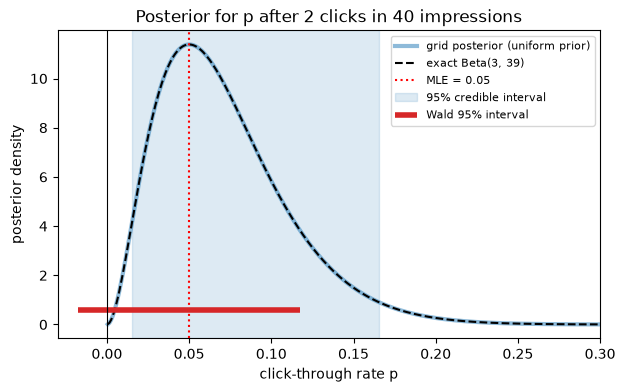


grid: mean 0.0714, 95% CI [0.0155, 0.1655]
Beta(3,39): mean 0.0714, median 0.0647, mode 0.0500, 95% CI [0.0154 0.1653]
P(p > 0.10 | data) = 0.2086     P(p > 0.04 | data) = 0.7750
Wald interval: 0.050 +/- 1.96 x 0.0345 = [-0.0175, 0.1175]   <- includes negative rates


In [12]:
k_c, n_c = 2, 40
p_vals = np.array([0.02, 0.05, 0.10]); prior3 = np.array([0.25, 0.50, 0.25])
lik3 = comb(n_c, k_c) * p_vals**k_c * (1 - p_vals)**(n_c - k_c)
joint3 = prior3 * lik3
evidence3 = joint3.sum()
post3 = joint3 / evidence3
print("three-point prior")
print(f"  likelihoods     {lik3.round(4)}")
print(f"  prior x lik     {joint3.round(4)}   evidence p(D) = {evidence3:.4f}")
print(f"  posterior       {post3.round(3)}   posterior mean = {(post3 * p_vals).sum():.4f}")

# grid posterior with a uniform prior (1,000 hypotheses) vs the exact Beta(3, 39)
grid = np.linspace(0.0005, 0.9995, 1000)
prior_g = np.ones_like(grid) / len(grid)
lik_g = comb(n_c, k_c) * grid**k_c * (1 - grid)**(n_c - k_c)
post_g = prior_g * lik_g; post_g /= post_g.sum()
post_exact = stats.beta(k_c + 1, n_c - k_c + 1)
cdf_g = np.cumsum(post_g)
ci_grid = (grid[np.searchsorted(cdf_g, 0.025)], grid[np.searchsorted(cdf_g, 0.975)])
se_wald = np.sqrt((k_c/n_c) * (1 - k_c/n_c) / n_c)

plt.plot(grid, post_g * len(grid), label="grid posterior (uniform prior)", lw=3, alpha=0.5)
plt.plot(grid, post_exact.pdf(grid), "k--", label="exact Beta(3, 39)")
plt.axvline(k_c / n_c, color="r", ls=":", label=f"MLE = {k_c/n_c}")
plt.axvspan(*post_exact.ppf([0.025, 0.975]), alpha=0.15, color="C0", label="95% credible interval")
plt.plot([k_c/n_c - 1.96*se_wald, k_c/n_c + 1.96*se_wald], [0.6, 0.6], "C3", lw=4, solid_capstyle="butt", label="Wald 95% interval")
plt.axvline(0, color="k", lw=0.8)
plt.xlim(-0.03, 0.3); plt.xlabel("click-through rate p"); plt.ylabel("posterior density"); plt.title("Posterior for p after 2 clicks in 40 impressions"); plt.legend(fontsize=8); plt.show()

print(f"\ngrid: mean {np.sum(grid * post_g):.4f}, 95% CI [{ci_grid[0]:.4f}, {ci_grid[1]:.4f}]")
print(f"Beta(3,39): mean {post_exact.mean():.4f}, median {post_exact.median():.4f}, mode {2/40:.4f}, 95% CI {post_exact.ppf([0.025, 0.975]).round(4)}")
print(f"P(p > 0.10 | data) = {1 - post_exact.cdf(0.10):.4f}     P(p > 0.04 | data) = {1 - post_exact.cdf(0.04):.4f}")
print(f"Wald interval: {k_c/n_c:.3f} +/- 1.96 x {se_wald:.4f} = [{k_c/n_c - 1.96*se_wald:.4f}, {k_c/n_c + 1.96*se_wald:.4f}]   <- includes negative rates")

The grid posterior and the exact Beta coincide — Bayes' theorem on a fine grid *is* the integral, done
numerically, and it works for any prior you can tabulate. The posterior is skewed: mode $0.05$ (the MLE),
median $0.065$, mean $0.071$, and a 21% probability that the true rate exceeds 10%. The Wald interval
$[-0.018, 0.118]$ (the red bar, which crosses zero) is a reminder that the asymptotics of Section 4 have not
arrived at $n = 40$, while the posterior is exact at any $n$.

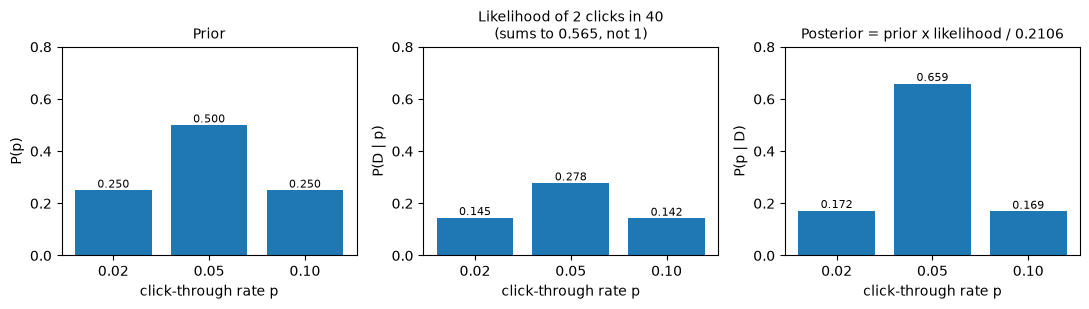

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
titles = ("Prior", f"Likelihood of {k_c} clicks in {n_c}\n(sums to {lik3.sum():.3f}, not 1)", f"Posterior = prior x likelihood / {evidence3:.4f}")
for ax, vals, title, ylab in zip(axes, (prior3, lik3, post3), titles, ("P(p)", "P(D | p)", "P(p | D)")):
    bars = ax.bar([f"{v:.2f}" for v in p_vals], vals)
    ax.bar_label(bars, fmt="%.3f", fontsize=8); ax.set_ylim(0, 0.8)
    ax.set_title(title, fontsize=10); ax.set_xlabel("click-through rate p"); ax.set_ylabel(ylab)
plt.tight_layout(); plt.show()

**Notice that** the likelihoods at 2% and 10% are almost equal (0.145 and 0.142), so the data cannot separate
them and both fall together, from 0.25 to about 0.17. The 5% hypothesis gains, from 0.50 to 0.66, because its likelihood is about twice
theirs. The middle panel does not sum to 1: only after multiplying by the prior and dividing by the evidence do
we get a distribution.

## 7. Conjugate updating: Beta–Binomial and Normal–Normal

A Beta$(a, b)$ prior updated with $k$ successes in $n$ trials gives Beta$(a + k, b + n - k)$, whose mean is
a weighted average of the prior mean and $k/n$ with data weight $n/(a + b + n)$. We start from the sceptical
prior Beta$(2, 8)$ (mean 0.2, worth 10 pseudo-flips) and feed in flips from a coin with $p = 0.7$ —
snapshots after 0, 5, 20 and 100 flips — then verify that updating one flip at a time ends at the same
posterior as one batch update. Finally the Normal–Normal case: precisions add, means are precision-weighted.

after   0 flips ( 0 heads): posterior mean 0.2000 = no data yet + 1.000 x 0.2 (prior);  95% CI [0.028, 0.482]
after   5 flips ( 4 heads): posterior mean 0.4000 = 0.333 x 0.800 (data) + 0.667 x 0.2 (prior);  95% CI [0.177, 0.649]


after  20 flips (16 heads): posterior mean 0.6000 = 0.667 x 0.800 (data) + 0.333 x 0.2 (prior);  95% CI [0.423, 0.765]
after 100 flips (66 heads): posterior mean 0.6182 = 0.909 x 0.660 (data) + 0.091 x 0.2 (prior);  95% CI [0.526, 0.706]


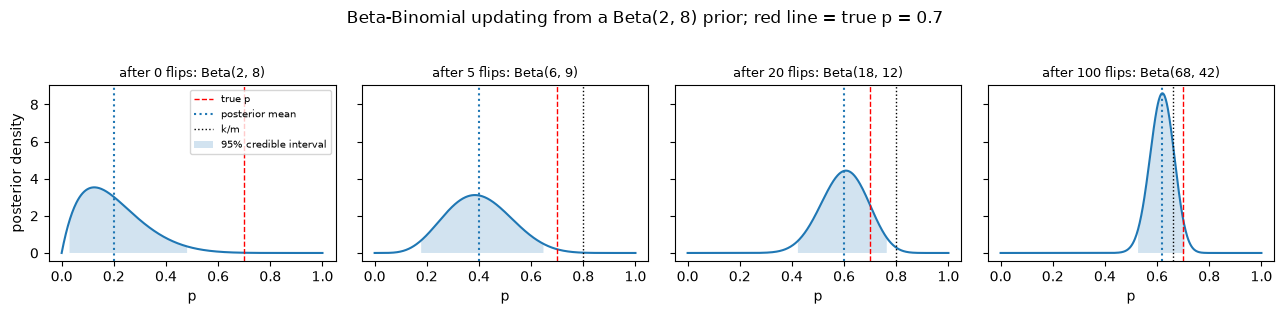


sequential (100 single-flip updates): Beta(68, 42);  batch: Beta(68, 42)  -> identical


In [14]:
a0, b0, p_coin = 2, 8, 0.7
flips = rng.random(100) < p_coin
p_axis = np.linspace(0, 1, 500)

fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, m in zip(axes, (0, 5, 20, 100)):
    k_m = flips[:m].sum()
    a_m, b_m = a0 + k_m, b0 + m - k_m
    ax.plot(p_axis, stats.beta.pdf(p_axis, a_m, b_m))
    ax.axvline(p_coin, color="r", ls="--", lw=1, label="true p")
    ax.axvline(a_m / (a_m + b_m), color="C0", ls=":", lw=1.5, label="posterior mean")
    if m:
        ax.axvline(k_m / m, color="k", ls=":", lw=1, label="k/m")
    else:
        ax.plot([], [], "k:", lw=1, label="k/m")                 # no data yet, but keep the legend entry
    ax.fill_between(p_axis, 0, stats.beta.pdf(p_axis, a_m, b_m), where=(p_axis > stats.beta.ppf(0.025, a_m, b_m)) & (p_axis < stats.beta.ppf(0.975, a_m, b_m)), alpha=0.2, label="95% credible interval")
    ax.set_title(f"after {m} flips: Beta({a_m}, {b_m})", fontsize=9); ax.set_xlabel("p")
    w_data = m / (a0 + b0 + m)
    data_part = f"{w_data:.3f} x {k_m/m:.3f} (data)" if m else "no data yet"
    print(f"after {m:3d} flips ({k_m:2d} heads): posterior mean {a_m/(a_m+b_m):.4f} = {data_part} + {1-w_data:.3f} x {a0/(a0+b0):.1f} (prior);"
          f"  95% CI [{stats.beta.ppf(0.025, a_m, b_m):.3f}, {stats.beta.ppf(0.975, a_m, b_m):.3f}]")
axes[0].set_ylabel("posterior density"); axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle(f"Beta-Binomial updating from a Beta({a0}, {b0}) prior; red line = true p = {p_coin}", y=1.03)
plt.tight_layout(); plt.show()

# sequential == batch
a_seq, b_seq = a0, b0
for f_ in flips:
    a_seq, b_seq = a_seq + int(f_), b_seq + 1 - int(f_)
print(f"\nsequential ({len(flips)} single-flip updates): Beta({a_seq}, {b_seq});  batch: Beta({a0 + flips.sum()}, {b0 + len(flips) - flips.sum()})  -> identical")

precisions: prior 0.0100 + data 0.2500 = posterior 0.2600  ->  posterior sd 1.961
posterior mean = 107.692   (data weight 0.962)


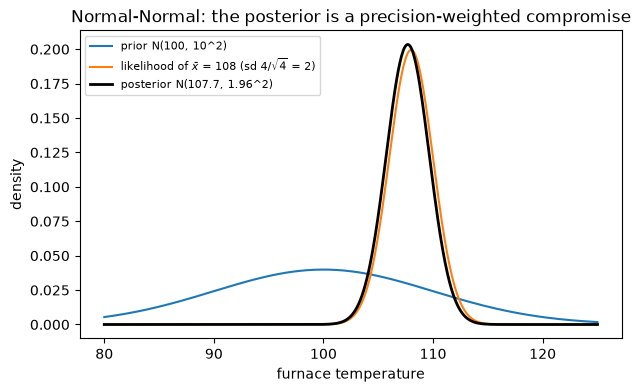

In [15]:
# Normal-Normal with known sensor noise: prior N(100, 10^2), four readings with sigma = 4 averaging 108
mu0, tau2, sigma2_s, n_r, xbar_r = 100.0, 10.0**2, 4.0**2, 4, 108.0
prec_prior, prec_data = 1/tau2, n_r/sigma2_s
prec_post = prec_prior + prec_data
mu_post = (prec_prior * mu0 + prec_data * xbar_r) / prec_post
print(f"precisions: prior {prec_prior:.4f} + data {prec_data:.4f} = posterior {prec_post:.4f}  ->  posterior sd {np.sqrt(1/prec_post):.3f}")
print(f"posterior mean = {mu_post:.3f}   (data weight {prec_data/prec_post:.3f})")

t_axis = np.linspace(80, 125, 600)
plt.plot(t_axis, stats.norm.pdf(t_axis, mu0, np.sqrt(tau2)), label="prior N(100, 10^2)")
plt.plot(t_axis, stats.norm.pdf(t_axis, xbar_r, np.sqrt(sigma2_s/n_r)), label=r"likelihood of $\bar x$ = 108 (sd 4/$\sqrt{4}$ = 2)")
plt.plot(t_axis, stats.norm.pdf(t_axis, mu_post, np.sqrt(1/prec_post)), "k", lw=2, label=f"posterior N({mu_post:.1f}, {np.sqrt(1/prec_post):.2f}^2)")
plt.xlabel("furnace temperature"); plt.ylabel("density"); plt.title("Normal-Normal: the posterior is a precision-weighted compromise"); plt.legend(fontsize=8); plt.show()

The four panels tell the shrinkage story: the prior pulls the first few estimates toward 0.2, but by 100
flips the data carry $100/110 = 91\%$ of the weight. In this run the posterior mean has climbed to about 0.62,
still pulled below the sample proportion 0.66 by the prior, and the true $p = 0.7$ lies just inside the 95%
band (the printout has the exact numbers). Sequential and batch updates land on the same Beta — the likelihood
factorises, so the order of arrival is irrelevant. In the Normal case the posterior is narrower than *both* the
prior and the likelihood (precisions add), and its mean is almost the data mean because the sensor is far more
precise than the prior.

true p outside the 95% band at flips: [0, 1, 2, 3, 4, 5, 6, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 89]
at the last flip: k/m = 0.660, posterior mean = 0.618, 95% band [0.526, 0.706], P(p < 0.7) = 0.965
Beta(2, 8): posterior mean after 1,000 flips = 0.698
Beta(1, 1): posterior mean after 1,000 flips = 0.703
Beta(8, 2): posterior mean after 1,000 flips = 0.704
Beta(20, 80): posterior mean after 1,000 flips = 0.657
Beta(20, 80) first passes 0.5 at flip 133


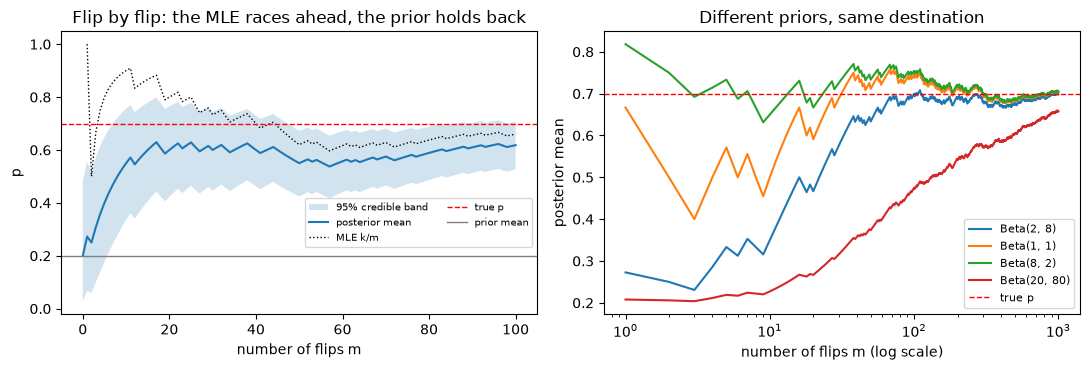

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

# left: the same flips as above, one at a time (consumes no random numbers)
m_axis = np.arange(len(flips) + 1)
k_cum = np.r_[0, np.cumsum(flips)]
a_tr, b_tr = a0 + k_cum, b0 + m_axis - k_cum
lo_tr, hi_tr = stats.beta.ppf(0.025, a_tr, b_tr), stats.beta.ppf(0.975, a_tr, b_tr)
ax1.fill_between(m_axis, lo_tr, hi_tr, alpha=0.2, label="95% credible band")
ax1.plot(m_axis, a_tr / (a_tr + b_tr), "C0", label="posterior mean")
ax1.plot(m_axis[1:], k_cum[1:] / m_axis[1:], "k:", lw=1, label="MLE k/m")
ax1.axhline(p_coin, color="r", ls="--", lw=1, label="true p")
ax1.axhline(a0 / (a0 + b0), color="0.5", lw=1, label="prior mean")
ax1.set_xlabel("number of flips m"); ax1.set_ylabel("p"); ax1.set_title("Flip by flip: the MLE races ahead, the prior holds back")
ax1.legend(fontsize=7, ncol=2, loc="lower right", bbox_to_anchor=(1, 0.22))
outside = m_axis[(p_coin < lo_tr) | (p_coin > hi_tr)]
print(f"true p outside the 95% band at flips: {outside.tolist()}")
print(f"at the last flip: k/m = {k_cum[-1]/m_axis[-1]:.3f}, posterior mean = {a_tr[-1]/(a_tr[-1]+b_tr[-1]):.3f}, 95% band [{lo_tr[-1]:.3f}, {hi_tr[-1]:.3f}], P(p < {p_coin}) = {stats.beta.cdf(p_coin, a_tr[-1], b_tr[-1]):.3f}")

# right: 1,000 fresh flips under four priors (a local generator, so the shared rng stream is untouched)
fl = np.random.default_rng(7).random(1000) < p_coin
mm = np.arange(1, 1001); kk = np.cumsum(fl)
for a_, b_ in ((2, 8), (1, 1), (8, 2), (20, 80)):
    post_mean = (a_ + kk) / (a_ + b_ + mm)
    ax2.semilogx(mm, post_mean, label=f"Beta({a_}, {b_})")
    print(f"Beta({a_}, {b_}): posterior mean after 1,000 flips = {post_mean[-1]:.3f}")
ax2.axhline(p_coin, color="r", ls="--", lw=1, label="true p")
ax2.set_xlabel("number of flips m (log scale)"); ax2.set_ylabel("posterior mean"); ax2.set_title("Different priors, same destination"); ax2.legend(fontsize=8)
print(f"Beta(20, 80) first passes 0.5 at flip {mm[np.argmax((20 + kk) / (100 + mm) > 0.5)]}")
plt.tight_layout(); plt.show()

**Notice that** the posterior mean always lies between the prior mean and the MLE, and the prior's share is
$10/(10 + m)$. The 95% band is not a guarantee: in this run the true 0.7 lies outside it for the first few
flips, when the prior dominates, and again around flips 48–89, because the sample ran low. On the right, after 1,000 flips three priors agree within 0.006 (0.698, 0.703,
0.704), while the 100-pseudo-count Beta$(20, 80)$ is still at 0.657; it passed 0.5 only at flip 133 in this
draw.

**Try it yourself:** change the prior to Beta$(20, 80)$ in the first cell of this section (same mean, ten times
the pseudo-count). How many flips does it take before the posterior mean passes 0.5? Solve
$(20 + 0.7m)/(100 + m) = 0.5$ by hand for the expected answer, then raise the 100 in `flips` to 300 and read the
crossing off the left panel above.

## 8. MAP with a Gaussian prior is ridge regression

Polynomial regression of degree 9 on 15 noisy points — a recipe for overfitting under maximum likelihood.
Put a Gaussian prior $w_j \sim \mathcal{N}(0, \tau^2)$ on the coefficients. The MAP estimate minimises
$\|y - Xw\|^2 + \lambda\|w\|^2$ with $\lambda = \sigma^2/\tau^2$, and we confirm that our closed-form
$(X^\top X + \lambda I)^{-1}X^\top y$ equals `sklearn.linear_model.Ridge(alpha=λ)` as $\tau$ varies.

     tau lambda = sigma^2/tau^2    ||w||  max |w_j|  RMSE vs truth   max |w_ours - w_sklearn|
    1000                  9e-08   168.70     121.51          0.197                   1.54e-08
       1                   0.09     2.28       2.06          0.166                   3.44e-15
     0.1                      9     0.40       0.37          0.578                   4.16e-17
    0.01                    900     0.01       0.01          0.740                   4.34e-19


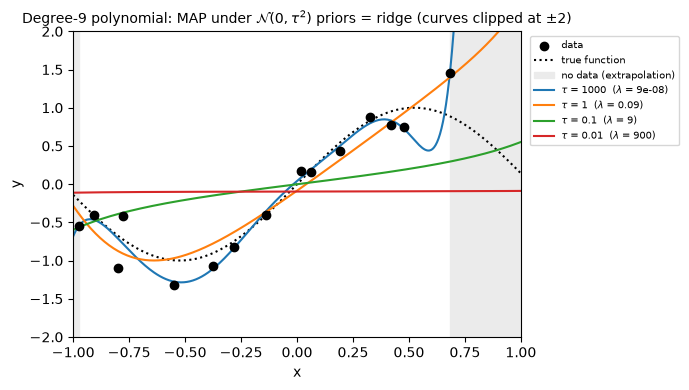

In [17]:
from sklearn.linear_model import Ridge

n_poly, degree, sigma_noise = 15, 9, 0.3
x_p = np.sort(rng.uniform(-1, 1, size=n_poly))
f_true = lambda x: np.sin(3 * x)
y_p = f_true(x_p) + rng.normal(0, sigma_noise, size=n_poly)
Phi = np.vander(x_p, degree + 1, increasing=True)[:, 1:]        # x, x^2, ..., x^9 (intercept handled separately)
xx = np.linspace(-1, 1, 300); Phi_xx = np.vander(xx, degree + 1, increasing=True)[:, 1:]

def map_fit(Phi, y, lam):
    # centre so that the intercept is unpenalised (matches Ridge(fit_intercept=True))
    Pm, ym = Phi.mean(axis=0), y.mean()
    Pc, yc = Phi - Pm, y - ym
    w = np.linalg.solve(Pc.T @ Pc + lam * np.eye(Phi.shape[1]), Pc.T @ yc)
    return w, ym - Pm @ w

in_range = (xx >= x_p.min()) & (xx <= x_p.max())              # score only where there are data, not the extrapolation
rmse_truth = lambda w_, b_: np.sqrt(np.mean((Phi_xx @ w_ + b_ - f_true(xx))[in_range]**2))
plt.scatter(x_p, y_p, color="k", zorder=3, label="data"); plt.plot(xx, f_true(xx), "k:", label="true function")
plt.axvspan(-1, x_p.min(), color="0.92"); plt.axvspan(x_p.max(), 1, color="0.92", label="no data (extrapolation)")
print(f"{'tau':>8s} {'lambda = sigma^2/tau^2':>22s} {'||w||':>8s} {'max |w_j|':>10s} {'RMSE vs truth':>14s} {'max |w_ours - w_sklearn|':>26s}")
for tau in (1e3, 1.0, 0.1, 0.01):
    lam = sigma_noise**2 / tau**2
    w_map, b_map = map_fit(Phi, y_p, lam)
    ridge = Ridge(alpha=lam).fit(Phi, y_p)
    plt.plot(xx, Phi_xx @ w_map + b_map, label=rf"$\tau$ = {tau:g}  ($\lambda$ = {lam:g})")
    print(f"{tau:8g} {lam:22.3g} {np.linalg.norm(w_map):8.2f} {np.abs(w_map).max():10.2f} {rmse_truth(w_map, b_map):14.3f} {np.max(np.abs(w_map - ridge.coef_)):26.2e}")
plt.xlim(-1, 1); plt.ylim(-2, 2); plt.xlabel("x"); plt.ylabel("y")
plt.title(r"Degree-9 polynomial: MAP under $\mathcal{N}(0,\tau^2)$ priors = ridge (curves clipped at $\pm 2$)", fontsize=10)
plt.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

With $\tau = 1000$ the prior is effectively flat, $\lambda \approx 10^{-7}$, and the MAP is the MLE: a
wiggly degree-9 curve that threads the noise, with a coefficient over 100 and a norm near 170. Tightening $\tau$
to $1$ gives $\lambda = 0.09$ and a smooth fit close to the truth. At $\tau = 0.1$ ($\lambda = 9$) the fit already
underfits, and $\tau = 0.01$ is nearly flat; the RMSE column rests these judgements on numbers. The grey bands
have no data, so what the curves do there is extrapolation, not overfitting of the points. The last column shows
our normal-equations solution matching scikit-learn's `Ridge` to about $10^{-8}$ at the ill-conditioned
$\tau = 1000$ and to machine precision for the others — the regulariser *is* the prior.

**Try it yourself:** multiply the data fivefold (`n_poly = 75`) and keep $\tau = 0.1$. The same prior now
shrinks far less, because the data term has five times as many summands.

tau = 1000: lambda = 9e-08, RMSE on the points 0.144, RMSE against the truth 0.197, ||w|| = 169
tau = 1: lambda = 0.09, RMSE on the points 0.232, RMSE against the truth 0.166, ||w|| = 2.28
tau = 0.1: lambda = 9, RMSE on the points 0.631, RMSE against the truth 0.578, ||w|| = 0.395
tau = 0.01: lambda = 900, RMSE on the points 0.802, RMSE against the truth 0.740, ||w|| = 0.00689
best on this grid: lambda = 0.0126 (tau = 2.67), RMSE against the truth 0.131


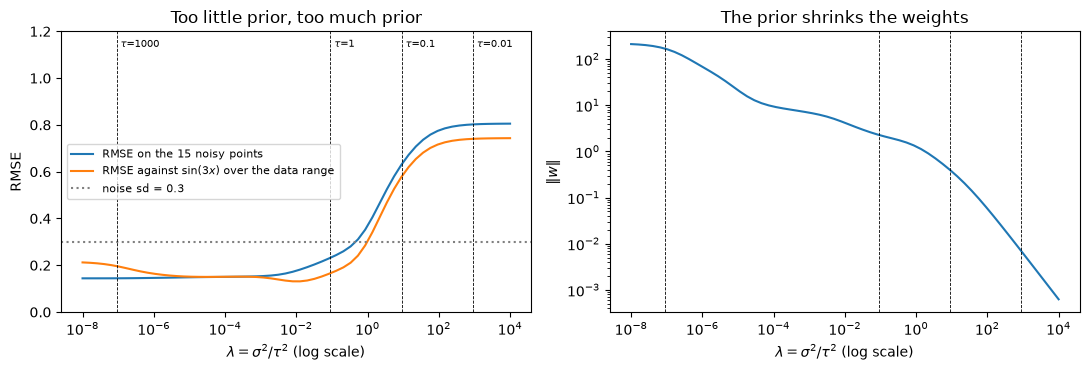

In [18]:
lams = np.logspace(-8, 4, 60)
fits = [map_fit(Phi, y_p, l_) for l_ in lams]
rmse_data = [np.sqrt(np.mean((Phi @ w_ + b_ - y_p)**2)) for w_, b_ in fits]
rmse_true = [rmse_truth(w_, b_) for w_, b_ in fits]
norms = [np.linalg.norm(w_) for w_, _ in fits]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.semilogx(lams, rmse_data, "C0", label=f"RMSE on the {n_poly} noisy points")
ax1.semilogx(lams, rmse_true, "C1", label=r"RMSE against $\sin(3x)$ over the data range")
ax1.axhline(sigma_noise, color="0.5", ls=":", label=f"noise sd = {sigma_noise}")
ax2.loglog(lams, norms, "C0")
for tau in (1e3, 1.0, 0.1, 0.01):
    lam = sigma_noise**2 / tau**2
    w_, b_ = map_fit(Phi, y_p, lam)
    for ax in (ax1, ax2):
        ax.axvline(lam, color="k", ls="--", lw=0.6)
    ax1.text(lam * 1.3, 1.13, rf"$\tau$={tau:g}", fontsize=7)
    print(f"tau = {tau:g}: lambda = {lam:g}, RMSE on the points {np.sqrt(np.mean((Phi @ w_ + b_ - y_p)**2)):.3f}, RMSE against the truth {rmse_truth(w_, b_):.3f}, ||w|| = {np.linalg.norm(w_):.3g}")
i_best = int(np.argmin(rmse_true))
print(f"best on this grid: lambda = {lams[i_best]:.3g} (tau = {sigma_noise / np.sqrt(lams[i_best]):.2f}), RMSE against the truth {rmse_true[i_best]:.3f}")
ax1.set_ylim(0, 1.2); ax1.set_xlabel(r"$\lambda = \sigma^2/\tau^2$ (log scale)"); ax1.set_ylabel("RMSE")
ax1.set_title("Too little prior, too much prior"); ax1.legend(fontsize=8, loc="center left")
ax2.set_xlabel(r"$\lambda = \sigma^2/\tau^2$ (log scale)"); ax2.set_ylabel(r"$\|w\|$"); ax2.set_title("The prior shrinks the weights")
plt.tight_layout(); plt.show()

**Notice that** training error only rises with $\lambda$, while error against the truth has a shallow
minimum of 0.13 near $\tau \approx 3$, is about 0.15 for $\tau$ from 10 to 100 and 0.17 at $\tau = 1$, and climbs
steeply once $\tau$ reaches 0.1 (0.58) and 0.01 (0.74), where the fit
is collapsing toward a constant. $\|w\|$ falls from about 170 at $\tau = 1000$ to about 0.4 at $\tau = 0.1$ and
0.007 at $\tau = 0.01$. This is the bias–variance trade-off of [Module 10](../10-estimation-and-sampling/README.md)
seen from the Bayesian side: a tighter prior trades variance for bias.

## 9. Posterior predictive versus plug-in prediction

With the Beta$(3, 39)$ posterior from Section 6, how many clicks will the next 100 impressions bring? The
plug-in answer is Binomial$(100, \hat p)$ with $\hat p$ the posterior mean. The honest answer integrates
over $p$: a Beta-Binomial distribution, which we obtain both from `scipy.stats.betabinom` and by brute
force — sample $p$ from the posterior, then sample clicks given $p$. We also revisit the zero-failure
problem.

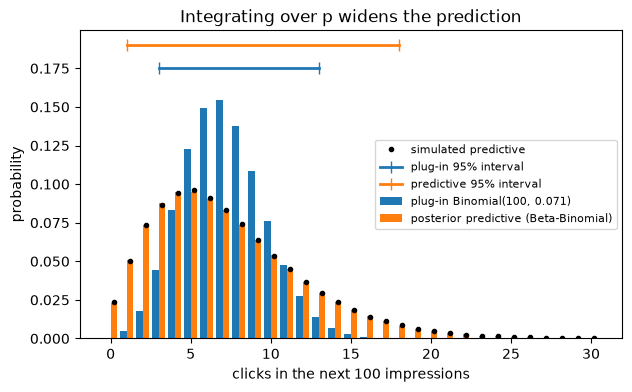

plug-in:    mean 7.14, sd 2.58, 95% interval [ 3 13]
predictive: mean 7.14, sd 4.68, 95% interval [ 1 18]
simulated:  mean 7.15, sd 4.69, 95% interval [ 1 18]
variance inflation factor (a+b+m)/(a+b+1) = 3.302

zero failures in 20 stress tests, uniform prior -> posterior Beta(1, 21)
  P(next fails)              rule of succession (k+1)/(n+2) = 0.0455      plug-in MLE = 0
  P(no failure in next 10)   predictive = B(1,31)/B(1,21) = 0.6774        plug-in = 1
  95% upper credible bound for the failure rate: 0.1329   (rule of three 3/n = 0.150)


In [19]:
a_post, b_post, m_future = 3, 39, 100
p_bar = a_post / (a_post + b_post)
plug_in = stats.binom(m_future, p_bar)
predictive = stats.betabinom(m_future, a_post, b_post)

# the same predictive by simulation: draw p from the posterior, then clicks given p
p_draws = rng.beta(a_post, b_post, size=200_000)
clicks_sim = rng.binomial(m_future, p_draws)

ks = np.arange(0, 31)
plt.bar(ks - 0.2, plug_in.pmf(ks), width=0.4, label=f"plug-in Binomial(100, {p_bar:.3f})")
plt.bar(ks + 0.2, predictive.pmf(ks), width=0.4, label="posterior predictive (Beta-Binomial)")
plt.plot(ks + 0.2, np.bincount(clicks_sim, minlength=200)[:31] / len(clicks_sim), "k.", label="simulated predictive")
plt.plot(plug_in.ppf([0.025, 0.975]), [0.175, 0.175], "C0|-", lw=2, ms=8, label="plug-in 95% interval")
plt.plot(predictive.ppf([0.025, 0.975]), [0.19, 0.19], "C1|-", lw=2, ms=8, label="predictive 95% interval")
plt.xlabel("clicks in the next 100 impressions"); plt.ylabel("probability"); plt.title("Integrating over p widens the prediction"); plt.legend(fontsize=8); plt.show()

print(f"plug-in:    mean {plug_in.mean():.2f}, sd {plug_in.std():.2f}, 95% interval {plug_in.ppf([0.025, 0.975]).astype(int)}")
print(f"predictive: mean {predictive.mean():.2f}, sd {predictive.std():.2f}, 95% interval {predictive.ppf([0.025, 0.975]).astype(int)}")
print(f"simulated:  mean {clicks_sim.mean():.2f}, sd {clicks_sim.std():.2f}, 95% interval {np.percentile(clicks_sim, [2.5, 97.5]).astype(int)}")
print(f"variance inflation factor (a+b+m)/(a+b+1) = {(a_post + b_post + m_future)/(a_post + b_post + 1):.3f}")

# zero failures in 20 tests: plug-in says failure is impossible, the posterior predictive does not
print("\nzero failures in 20 stress tests, uniform prior -> posterior Beta(1, 21)")
print(f"  P(next fails)              rule of succession (k+1)/(n+2) = {1/22:.4f}      plug-in MLE = 0")
print(f"  P(no failure in next 10)   predictive = B(1,31)/B(1,21) = {21/31:.4f}        plug-in = 1")
print(f"  95% upper credible bound for the failure rate: {stats.beta.ppf(0.95, 1, 21):.4f}   (rule of three 3/n = {3/20:.3f})")

The predictive distribution has the same mean as the plug-in but a standard deviation of 4.7 instead of
2.6, and a 95% interval of 1–18 clicks instead of 3–13: the plug-in interval is only about 60% as wide as it
should be, because it pretends $p$ is known. The simulated histogram (dots) sits on the Beta-Binomial bars —
"sample the parameter, then sample the data" is the posterior predictive integral done by Monte Carlo, and
it works for any model, conjugate or not. After zero failures in 20 tests the plug-in says failure is
impossible, while the predictive gives 4.5% for the next test and a 32% chance of at least one failure in the
next ten.

## 10. Bayesian A/B testing

A: 120 conversions in 2,400 visitors; B: 150 in 2,400. With uniform priors the posteriors are
Beta$(121, 2281)$ and Beta$(151, 2251)$. We estimate $P(p_B > p_A \mid \mathcal{D})$ by Monte Carlo, compute
the expected loss of each decision, and put the frequentist two-proportion $z$-test next to it to see how the
two answers differ in kind.

posterior means: A 0.0504, B 0.0629;  posterior sds: A 0.0045, B 0.0050
P(B > A | data) = 0.9698  (Monte Carlo SE 0.0003)
expected loss if we ship B: 0.00008   if we keep A: 0.01257   (ratio 164x)
mean shortfall given that B really is worse: 0.0025
95% credible interval for the lift p_B - p_A: [-0.0005, 0.0256]

frequentist: z = 1.879, two-sided p-value = 0.0602  -> 'not significant at 5%'


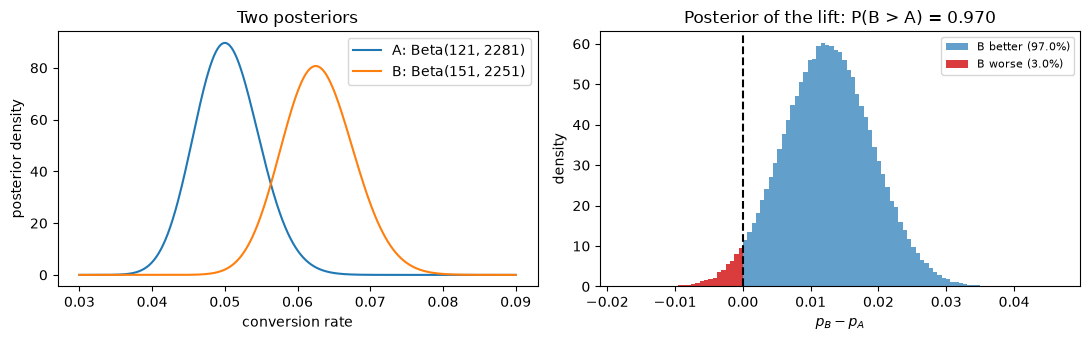

In [20]:
kA, nA, kB, nB = 120, 2400, 150, 2400
postA, postB = stats.beta(1 + kA, 1 + nA - kA), stats.beta(1 + kB, 1 + nB - kB)

S = 400_000
pA, pB = postA.rvs(S, random_state=rng), postB.rvs(S, random_state=rng)
prob_B_better = np.mean(pB > pA)
loss_choose_B = np.mean(np.maximum(pA - pB, 0))     # conversion forgone if B is actually worse
loss_choose_A = np.mean(np.maximum(pB - pA, 0))

print(f"posterior means: A {postA.mean():.4f}, B {postB.mean():.4f};  posterior sds: A {postA.std():.4f}, B {postB.std():.4f}")
print(f"P(B > A | data) = {prob_B_better:.4f}  (Monte Carlo SE {np.sqrt(prob_B_better*(1-prob_B_better)/S):.4f})")
print(f"expected loss if we ship B: {loss_choose_B:.5f}   if we keep A: {loss_choose_A:.5f}   (ratio {loss_choose_A/loss_choose_B:.0f}x)")
print(f"mean shortfall given that B really is worse: {np.mean((pA - pB)[pA > pB]):.4f}")
print(f"95% credible interval for the lift p_B - p_A: [{np.percentile(pB - pA, 2.5):.4f}, {np.percentile(pB - pA, 97.5):.4f}]")

# frequentist two-proportion z-test for comparison (Module 12)
p_pool = (kA + kB) / (nA + nB)
z = (kB/nB - kA/nA) / np.sqrt(p_pool * (1 - p_pool) * (1/nA + 1/nB))
p_value = 2 * (1 - stats.norm.cdf(abs(z)))
print(f"\nfrequentist: z = {z:.3f}, two-sided p-value = {p_value:.4f}  -> '{'significant' if p_value < 0.05 else 'not significant'} at 5%'")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
grid_ab = np.linspace(0.03, 0.09, 500)
ax1.plot(grid_ab, postA.pdf(grid_ab), label=f"A: Beta({1 + kA}, {1 + nA - kA})"); ax1.plot(grid_ab, postB.pdf(grid_ab), label=f"B: Beta({1 + kB}, {1 + nB - kB})")
ax1.set_xlabel("conversion rate"); ax1.set_ylabel("posterior density"); ax1.set_title("Two posteriors"); ax1.legend()
lift = pB - pA
step_ = (lift.max() - lift.min()) / 100                         # bins with an edge exactly at 0
edges = step_ * np.arange(np.floor(lift.min() / step_), np.ceil(lift.max() / step_) + 1)
heights, _ = np.histogram(lift, bins=edges, density=True)
worse = edges[:-1] < -step_ / 2
ax2.bar(edges[:-1][~worse], heights[~worse], width=step_, align="edge", color="C0", alpha=0.7, label=f"B better ({np.mean(lift > 0):.1%})")
ax2.bar(edges[:-1][worse], heights[worse], width=step_, align="edge", color="C3", alpha=0.9, label=f"B worse ({np.mean(lift < 0):.1%})")
ax2.axvline(0, color="k", ls="--"); ax2.legend(fontsize=8)
ax2.set_xlabel("$p_B - p_A$"); ax2.set_ylabel("density"); ax2.set_title(f"Posterior of the lift: P(B > A) = {prob_B_better:.3f}")
plt.tight_layout(); plt.show()

Both analyses are correct and they answer different questions. The posterior says: B is better with
probability 0.97, and the expected loss of shipping it, averaged over all outcomes (zero when B really is
better), is 0.008 percentage points, roughly 160 times smaller than the expected loss of keeping A. If B does
turn out worse, it is worse by about 0.25 points on average. The $z$-test says the data would be this extreme 6% of
the time if the rates were equal — not below 5%, so by that rule you would not reject equality. A decision
maker who needs to choose *now* wants the first pair of numbers; [Module 12](../12-hypothesis-testing-and-experiments/README.md)
explains when and why the second matters.

**Try it yourself:** multiply all four counts by 4 (same rates, four times the traffic). What happens to
$P(B > A)$, to the expected loss, and to the $p$-value?

## Summary

- The likelihood $L(\theta) = \prod_i p(x_i \mid \theta)$ ranks parameters by how well they explain the data; it is not a distribution over $\theta$ (the coin example integrates to $1/11$).
- Closed-form MLEs: $\hat p = k/n$, $\hat\lambda = \bar x$ (Poisson), $\hat\lambda = 1/\bar x$ (Exponential), $\hat\mu = \bar x$, $\hat\sigma^2 = \frac1n\sum(x_i - \bar x)^2$ — biased by $(n-1)/n$, confirmed by simulation.
- Without a closed form (Gamma shape, logistic regression), minimise the NLL numerically; reparameterise to respect constraints; Newton, BFGS and `scipy.stats.*.fit` agree.
- The Fisher information predicts the spread of the MLE: empirical standard deviations match $1/\sqrt{n\,i(\theta)}$ and Wald intervals cover ~95% for moderate $n$ when $p$ is not near 0 or 1.
- MSE and the Gaussian NLL have the same argmin; BCE equals the negative mean Bernoulli log-likelihood; gradient ascent on $\ell$ reproduces `LogisticRegression`.
- Posterior $\propto$ prior $\times$ likelihood, computable on a grid for any prior; conjugate pairs make it arithmetic on pseudo-counts, and sequential = batch.
- MAP with a Gaussian prior is ridge with $\lambda = \sigma^2/\tau^2$, verified against `Ridge` for several $\tau$.
- The posterior predictive is wider than the plug-in prediction (variance factor $(a+b+m)/(a+b+1)$) and never predicts "impossible" after zero failures.
- Bayesian A/B testing gives $P(B > A \mid \mathcal{D})$ and expected losses — a different question from the $p$-value, answered on the same data.

**Next:** open `exercises.ipynb` and work through the self-checked problems; the solutions notebook has reference implementations.